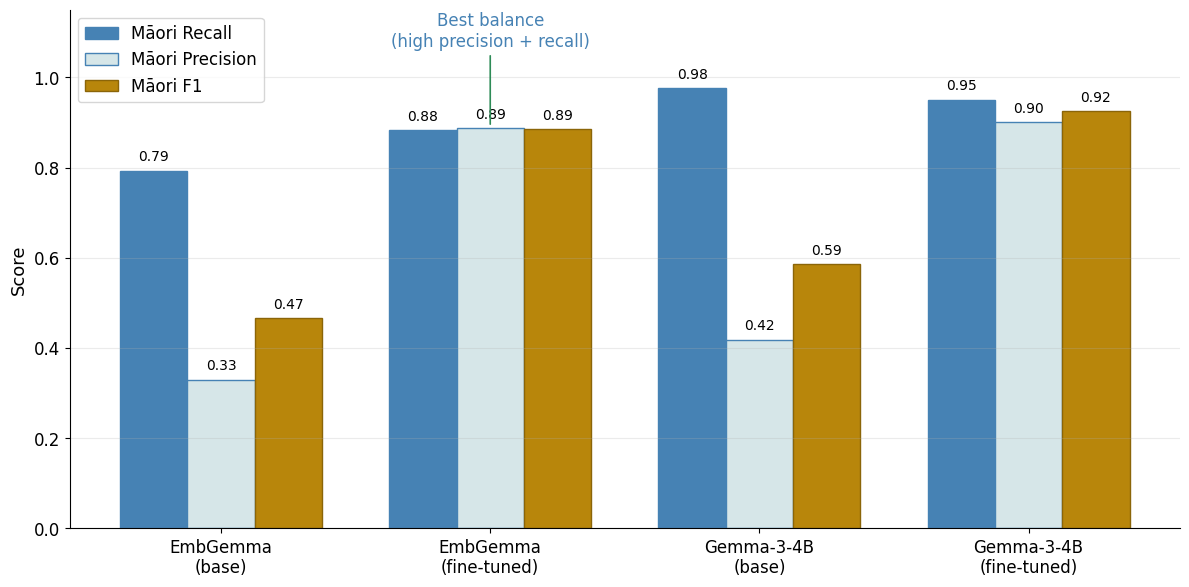

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

models = [
    "EmbGemma\n(base)",
    "EmbGemma\n(fine-tuned)",
    "Gemma-3-4B\n(base)",
    "Gemma-3-4B\n(fine-tuned)"
]

# Replace these with your actual Gemma-3-4B LoRA evaluation results
GEMMA_LORA_RECALL = 0.95
GEMMA_LORA_PRECISION = 0.90

maori_recall = np.array([
    0.7929,              # EmbGemma base
    0.8828,              # EmbGemma fine-tuned
    0.9755,              # Gemma-3-4B base
    GEMMA_LORA_RECALL    # Gemma-3-4B fine-tuned
])

maori_precision = np.array([
    0.3296,                 # EmbGemma base
    0.8877,                 # EmbGemma fine-tuned
    0.4182,                 # Gemma-3-4B base
    GEMMA_LORA_PRECISION    # Gemma-3-4B fine-tuned
])

maori_f1 = 2 * (maori_precision * maori_recall) / (maori_precision + maori_recall)

x = np.arange(len(models))
width = 0.25

plt.figure(figsize=(12, 6))

bars1 = plt.bar(
    x - width,
    maori_recall,
    width,
    label="Māori Recall",
    color="#4682B4",
    edgecolor="#4682B4"
)

bars2 = plt.bar(
    x,
    maori_precision,
    width,
    label="Māori Precision",
    color="#d6e6e8",
    edgecolor="#4682B4"
)

bars3 = plt.bar(
    x + width,
    maori_f1,
    width,
    label="Māori F1",
    color="#B8860B",
    edgecolor="#8B6508"
)

for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.015,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=10
        )

plt.annotate(
    "Best balance\n(high precision + recall)",
    xy=(1, 0.89),
    xytext=(1, 1.06),
    ha="center",
    va="bottom",
    fontsize=12,
    color="#4682B4",
    arrowprops=dict(
        arrowstyle="-",
        color="#2E8B57",
        linewidth=1.2
    )
)

plt.xticks(x, models, fontsize=12)
plt.yticks(fontsize=12)
plt.ylabel("Score", fontsize=13)
plt.ylim(0, 1.15)
plt.legend(loc="upper left", fontsize=12)
plt.grid(axis="y", linestyle="-", alpha=0.25)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig("fig_precision_recall_f1_with_gemma_lora.png", dpi=300, bbox_inches="tight")
plt.savefig("fig_precision_recall_f1_with_gemma_lora.pdf", bbox_inches="tight")

plt.show()

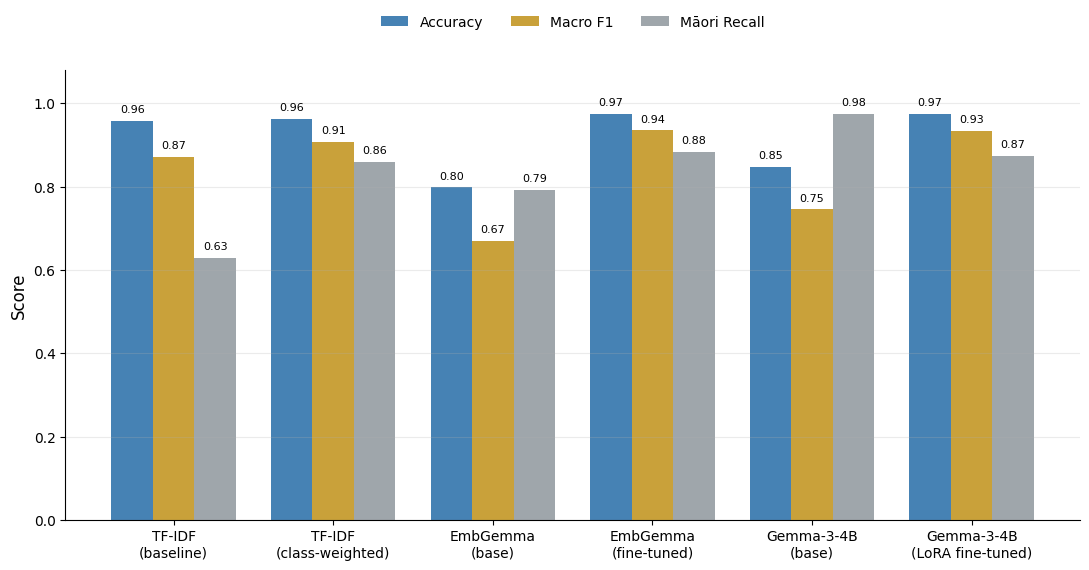

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# Model names
models = [
    "TF-IDF\n(baseline)",
    "TF-IDF\n(class-weighted)",
    "EmbGemma\n(base)",
    "EmbGemma\n(fine-tuned)",
    "Gemma-3-4B\n(base)",
    "Gemma-3-4B\n(LoRA fine-tuned)"
]

# Metrics from the 3,318-record held-out test set
accuracy = np.array([
    0.9578,
    0.9629,
    0.7987,
    0.9747,
    0.8472,
    0.9744
])

macro_f1 = np.array([
    0.8721,
    0.9081,
    0.6708,
    0.9355,
    0.7459,
    0.9343
])

maori_recall = np.array([
    0.6300,
    0.8600,
    0.7929,
    0.8828,
    0.9755,
    0.8747
])

x = np.arange(len(models))
width = 0.26

plt.figure(figsize=(11, 5.8))

# Bars
bars1 = plt.bar(
    x - width,
    accuracy,
    width,
    label="Accuracy",
    color="#4682B4"
)

bars2 = plt.bar(
    x,
    macro_f1,
    width,
    label="Macro F1",
    color="#c9a13a"
)

bars3 = plt.bar(
    x + width,
    maori_recall,
    width,
    label="Māori Recall",
    color="#9fa6ab"
)

# Add value labels
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            height + 0.015,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=8
        )

# Formatting
plt.ylabel("Score", fontsize=12)
plt.ylim(0, 1.08)
plt.xticks(x, models, fontsize=10)
plt.yticks(fontsize=10)

plt.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, 1.15),
    ncol=3,
    frameon=False,
    fontsize=10
)

plt.grid(axis="y", linestyle="-", alpha=0.25)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Save for paper
plt.savefig("fig_metrics_comparison.png", dpi=300, bbox_inches="tight")
plt.savefig("fig_metrics_comparison.pdf", bbox_inches="tight")

plt.show()

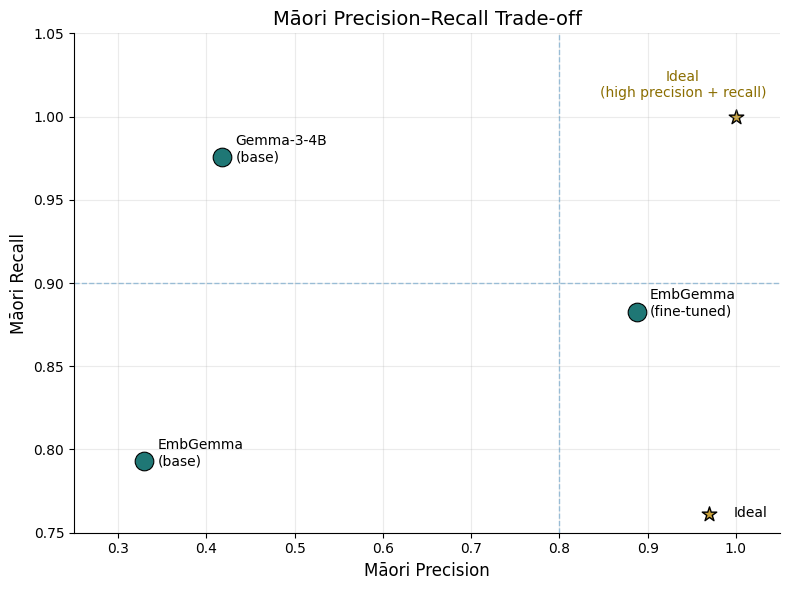

In [ ]:
import matplotlib.pyplot as plt

# Model results
models = [
    "EmbGemma\n(base)",
    "EmbGemma\n(fine-tuned)",
    "Gemma-3-4B\n(base)"
]

maori_precision = [0.3296, 0.8877, 0.4182]
maori_recall = [0.7929, 0.8828, 0.9755]

plt.figure(figsize=(8, 6))

# Scatter points
plt.scatter(
    maori_precision,
    maori_recall,
    s=180,
    color="#1f7775",
    edgecolor="black",
    linewidth=0.8
)

# Add labels beside points
for model, p, r in zip(models, maori_precision, maori_recall):
    plt.text(
        p + 0.015,
        r + 0.005,
        model,
        fontsize=10,
        ha="left",
        va="center"
    )

# Add ideal point marker
plt.scatter(
    [1.0],
    [1.0],
    s=120,
    marker="*",
    color="#c9a13a",
    edgecolor="black",
    label="Ideal"
)

plt.text(
    0.94,
    1.01,
    "Ideal\n(high precision + recall)",
    fontsize=10,
    ha="center",
    va="bottom",
    color="#8a6d00"
)

# Add guide lines
plt.axhline(0.9, linestyle="--", linewidth=1, alpha=0.4)
plt.axvline(0.8, linestyle="--", linewidth=1, alpha=0.4)

# Formatting
plt.xlabel("Māori Precision", fontsize=12)
plt.ylabel("Māori Recall", fontsize=12)
plt.title("Māori Precision–Recall Trade-off", fontsize=14)

plt.xlim(0.25, 1.05)
plt.ylim(0.75, 1.05)

plt.grid(alpha=0.25)
plt.legend(frameon=False, loc="lower right")

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

# Save for paper
plt.savefig("fig_precision_recall_tradeoff.png", dpi=300, bbox_inches="tight")
plt.savefig("fig_precision_recall_tradeoff.pdf", bbox_inches="tight")

plt.show()

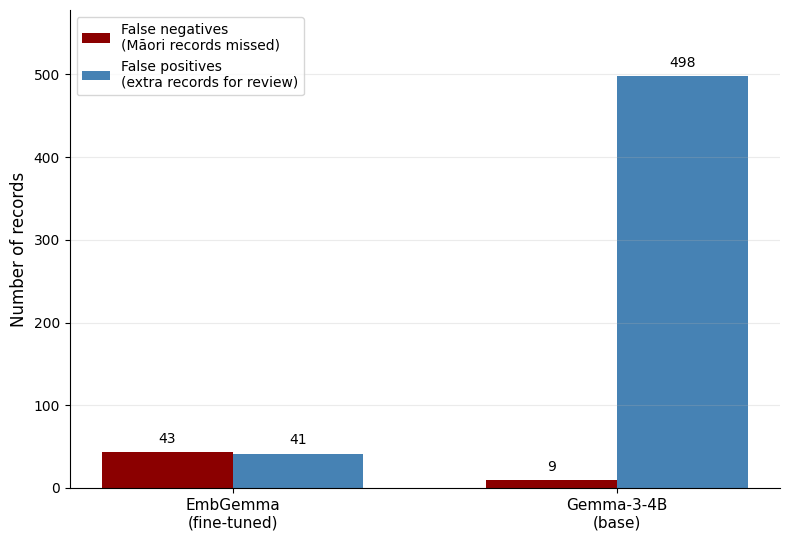

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Models with available/confident confusion data
models = [
    "EmbGemma\n(fine-tuned)",
    "Gemma-3-4B\n(base)"
]

# Known values
# EmbGemma fine-tuned confusion matrix:
# TP=324, FN=43, FP=41, TN=2910
#
# Gemma-3-4B base:
# True Māori = 367, recall = 0.9755 -> TP ≈ 358, FN = 9
# Precision = 0.4182, TP = 358 -> predicted Māori ≈ 856, FP ≈ 498
false_negatives = np.array([43, 9])
false_positives = np.array([41, 498])

x = np.arange(len(models))
width = 0.34

plt.figure(figsize=(8, 5.5))

bars1 = plt.bar(
    x - width/2,
    false_negatives,
    width,
    label="False negatives\n(Māori records missed)",
    color="#8B0000"
)

bars2 = plt.bar(
    x + width/2,
    false_positives,
    width,
    label="False positives\n(extra records for review)",
    color="#4682B4"
)

# Add labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width()/2,
            height + 8,
            f"{int(height)}",
            ha="center",
            va="bottom",
            fontsize=10
        )

plt.xticks(x, models, fontsize=11)
plt.ylabel("Number of records", fontsize=12)
plt.ylim(0, max(false_positives) + 80)

plt.legend(loc="upper left", fontsize=10)
plt.grid(axis="y", linestyle="-", alpha=0.25)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()

plt.savefig("fig_error_tradeoff.png", dpi=300, bbox_inches="tight")
plt.savefig("fig_error_tradeoff.pdf", bbox_inches="tight")

plt.show()

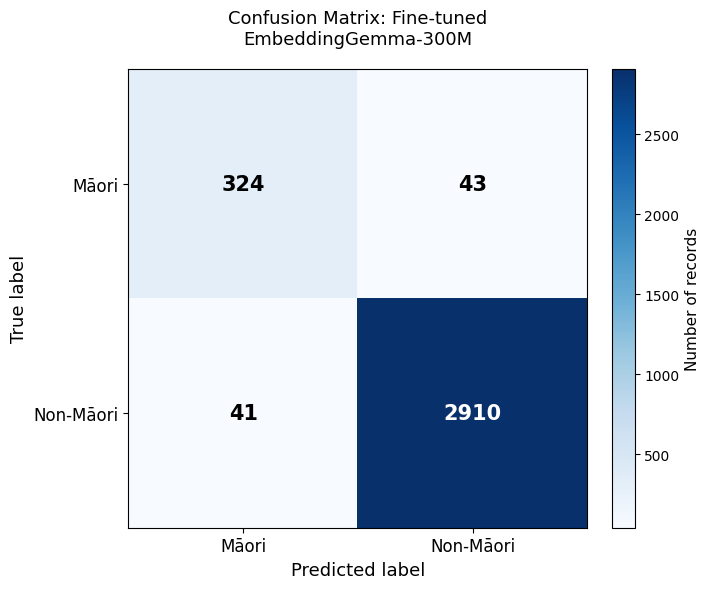

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import textwrap

cm = np.array([
    [324, 43],
    [41, 2910]
])

labels = ["Māori", "Non-Māori"]

fig, ax = plt.subplots(figsize=(7.5, 6))

im = ax.imshow(cm, cmap="Blues")

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        value = cm[i, j]
        ax.text(
            j,
            i,
            f"{value}",
            ha="center",
            va="center",
            fontsize=15,
            fontweight="bold",
            color="white" if value > cm.max() / 2 else "black"
        )

ax.set_xticks(np.arange(len(labels)))
ax.set_yticks(np.arange(len(labels)))
ax.set_xticklabels(labels, fontsize=12)
ax.set_yticklabels(labels, fontsize=12)

ax.set_xlabel("Predicted label", fontsize=13)
ax.set_ylabel("True label", fontsize=13)

title = "Confusion Matrix: Fine-tuned EmbeddingGemma-300M"
ax.set_title("\n".join(textwrap.wrap(title, width=42)), fontsize=13, pad=18)

cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.set_label("Number of records", fontsize=11)

fig.tight_layout()

plt.savefig("fig_confusion_matrix_embgemma_finetuned.png", dpi=300, bbox_inches="tight")
plt.savefig("fig_confusion_matrix_embgemma_finetuned.pdf", bbox_inches="tight")

plt.show()

Models plotted:
- EmbGemma-300M
(base)
- EmbGemma-300M
(fine-tuned)
- Gemma-3-4B
(base)


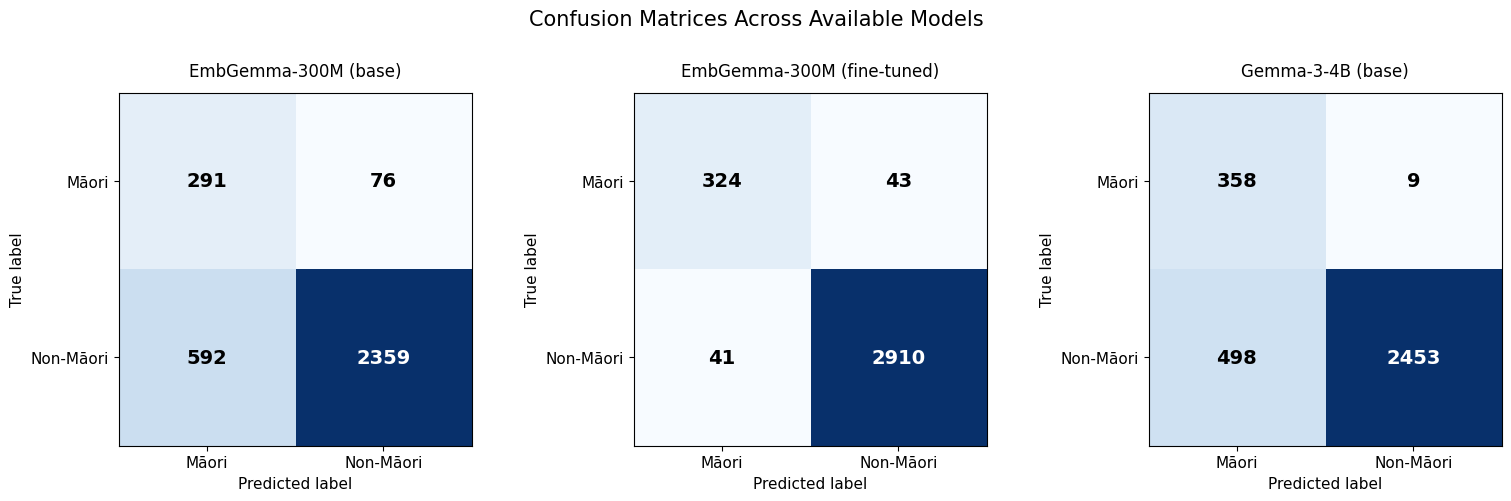

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import math
import textwrap

# Test set counts
TOTAL_MAORI = 367
TOTAL_NON_MAORI = 2951

def confusion_from_precision_recall(precision, recall, total_maori=TOTAL_MAORI, total_non_maori=TOTAL_NON_MAORI):
    """
    Build approximate confusion matrix from Māori precision and Māori recall.
    Rows: true labels [Māori, Non-Māori]
    Cols: predicted labels [Māori, Non-Māori]
    """
    tp = round(recall * total_maori)
    fn = total_maori - tp

    predicted_maori = round(tp / precision)
    fp = predicted_maori - tp
    tn = total_non_maori - fp

    return np.array([
        [tp, fn],
        [fp, tn]
    ])

# Add TF-IDF precision values when available.
# If precision is unknown, leave as None and the plot will skip that model.
model_data = {
    "TF-IDF LR\n(baseline)": {
        "precision": None,
        "recall": 0.63
    },
    "TF-IDF LR\n(class-weighted)": {
        "precision": None,
        "recall": 0.86
    },
    "EmbGemma-300M\n(base)": {
        "precision": 0.3296,
        "recall": 0.7929
    },
    "EmbGemma-300M\n(fine-tuned)": {
        # Known exact confusion matrix from your results
        "cm": np.array([
            [324, 43],
            [41, 2910]
        ])
    },
    "Gemma-3-4B\n(base)": {
        "precision": 0.4182,
        "recall": 0.9755
    },
    "Gemma-3-4B\n(LoRA fine-tuned)": {
        # Replace after LoRA evaluation
        "precision": None,
        "recall": None
    }
}

# Build confusion matrices
confusion_matrices = {}

for model, values in model_data.items():
    if "cm" in values:
        confusion_matrices[model] = values["cm"]
    else:
        precision = values.get("precision")
        recall = values.get("recall")

        if precision is not None and recall is not None:
            confusion_matrices[model] = confusion_from_precision_recall(precision, recall)

print("Models plotted:")
for model in confusion_matrices:
    print("-", model)

# Plot all available confusion matrices
n_models = len(confusion_matrices)
cols = 3
rows = math.ceil(n_models / cols)

fig, axes = plt.subplots(rows, cols, figsize=(cols * 5.2, rows * 4.8))

if rows == 1:
    axes = np.array([axes])
axes = axes.flatten()

labels = ["Māori", "Non-Māori"]

for ax, (model, cm) in zip(axes, confusion_matrices.items()):
    im = ax.imshow(cm, cmap="Blues")

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            value = cm[i, j]
            ax.text(
                j,
                i,
                f"{value}",
                ha="center",
                va="center",
                fontsize=14,
                fontweight="bold",
                color="white" if value > cm.max() / 2 else "black"
            )

    ax.set_xticks(np.arange(len(labels)))
    ax.set_yticks(np.arange(len(labels)))

    ax.set_xticklabels(labels, fontsize=11)
    ax.set_yticklabels(labels, fontsize=11)

    ax.set_xlabel("Predicted label", fontsize=11)
    ax.set_ylabel("True label", fontsize=11)

    title = model.replace("\n", " ")
    ax.set_title("\n".join(textwrap.wrap(title, width=32)), fontsize=12, pad=12)

# Remove empty axes
for ax in axes[n_models:]:
    ax.axis("off")

fig.suptitle(
    "Confusion Matrices Across Available Models",
    fontsize=15,
    y=1.02
)

fig.tight_layout()

plt.savefig("fig_confusion_matrices_all_models.png", dpi=300, bbox_inches="tight")
plt.savefig("fig_confusion_matrices_all_models.pdf", bbox_inches="tight")

plt.show()